In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Load dataset

In [2]:
from sklearn.datasets import fetch_california_housing
housing=fetch_california_housing(as_frame=True)
df=housing.frame

EDA

In [16]:
df.sample(5)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
4320,2.8021,47.0,3.765690,1.142259,921.0,1.926778,34.09,-118.35,2.806
14861,2.6190,20.0,4.326347,0.967066,573.0,1.715569,32.65,-117.09,1.458
16356,3.5379,26.0,5.713427,1.068136,1544.0,3.094188,38.02,-121.32,0.991
6151,3.1621,6.0,3.939516,1.076613,1584.0,3.193548,34.09,-117.96,1.310
20246,3.6413,40.0,4.604736,1.041894,1318.0,2.400729,34.27,-119.26,2.127


In [5]:
df.shape

(20640, 9)

In [6]:
df.columns

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [8]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [9]:
df.isnull().sum()

,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


EDA

In [10]:
df.duplicated().sum()

np.int64(0)

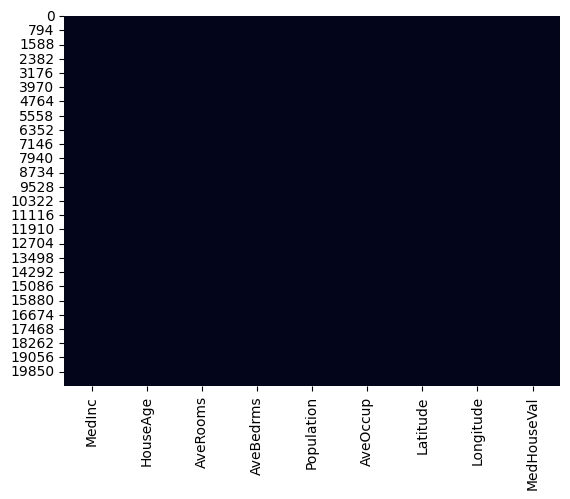

In [13]:
sns.heatmap(df.isnull(),cbar=False)
plt.show()

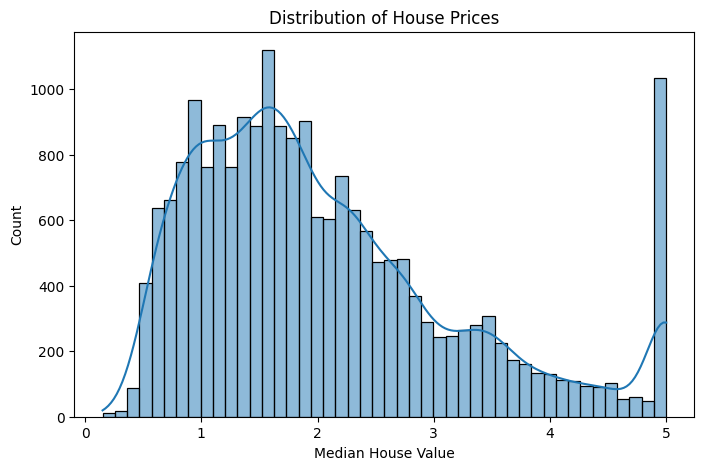

In [14]:
plt.figure(figsize=(8,5))

sns.histplot(df['MedHouseVal'], kde=True)

plt.title('Distribution of House Prices')
plt.xlabel('Median House Value')
plt.show()

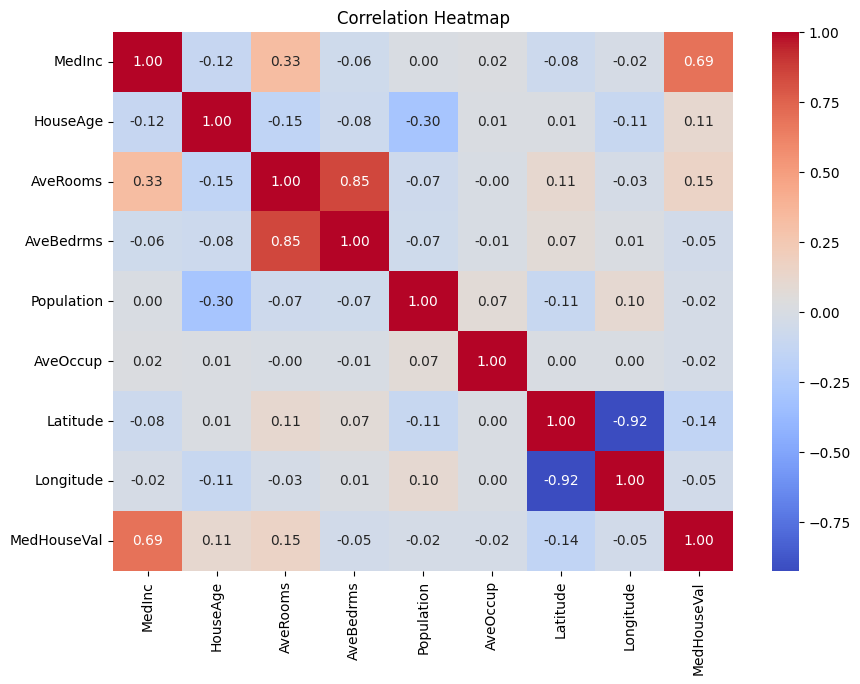

In [17]:
plt.figure(figsize=(10,7))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

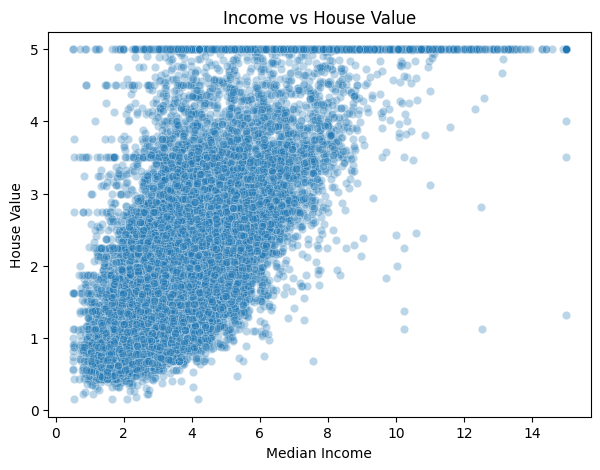

In [18]:
plt.figure(figsize=(7,5))

sns.scatterplot(
    x=df['MedInc'],
    y=df['MedHouseVal'],
    alpha=0.3
)

plt.xlabel('Median Income')
plt.ylabel('House Value')
plt.title('Income vs House Value')

plt.show()

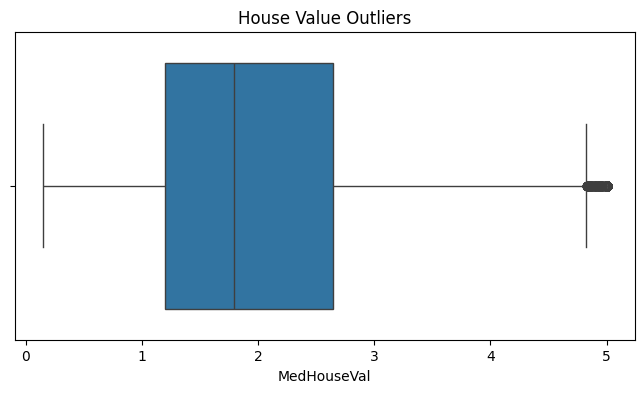

In [19]:
plt.figure(figsize=(8,4))

sns.boxplot(x=df['MedHouseVal'])

plt.title('House Value Outliers')
plt.show()

Feature selection

In [20]:
X = df.drop('MedHouseVal', axis=1)

y = df['MedHouseVal']

In [21]:
print(X.shape)
print(y.shape)

(20640, 8)
(20640,)


Train test split

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [23]:
print(X_train.shape)
print(X_test.shape)

(16512, 8)
(4128, 8)


create model

In [25]:
model = LinearRegression()
model.fit(X_train, y_train)
y_pred=model.predict(X_test)

In [26]:
y_pred

array([0.71912284, 1.76401657, 2.70965883, ..., 4.46877017, 1.18751119,
       2.00940251], shape=(4128,))

In [28]:
print(y_pred[:10])    # First 10 values

[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725 2.01175367
 2.64550005 2.16875532 2.74074644 3.91561473]


In [29]:
#compare
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

comparison.head(10)

,Actual,Predicted
0,0.47700,0.719123
1,0.45800,1.764017
2,5.00001,2.709659
3,2.18600,2.838926
4,2.78000,2.604657
5,1.58700,2.011754
6,1.98200,2.645500
7,1.57500,2.168755
8,3.40000,2.740746
9,4.46600,3.915615


In [30]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 0.5332001304956561
MSE: 0.5558915986952438
RMSE: 0.745581383012776
R2 Score: 0.5757877060324512


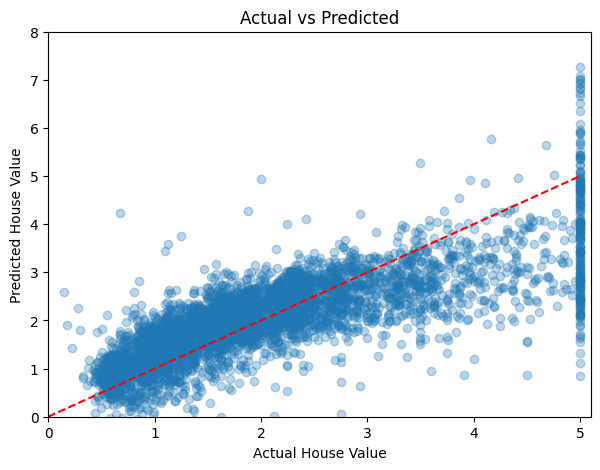

In [35]:
plt.figure(figsize=(7,5))

plt.scatter(y_test, y_pred, alpha=0.3)

plt.plot([0,5], [0,5], 'r--')

plt.xlim(0,5.1)
plt.ylim(0,8)

plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")

plt.title("Actual vs Predicted")
plt.show()

In [36]:
from sklearn.tree import DecisionTreeRegressor
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

In [37]:
dt_mae = mean_absolute_error(y_test, dt_pred)

dt_mse = mean_squared_error(y_test, dt_pred)

dt_rmse = np.sqrt(dt_mse)

dt_r2 = r2_score(y_test, dt_pred)

print("MAE:", dt_mae)
print("MSE:", dt_mse)
print("RMSE:", dt_rmse)
print("R2 Score:", dt_r2)

MAE: 0.45467918846899225
MSE: 0.495235205629094
RMSE: 0.7037294974840077
R2 Score: 0.622075845135081


In [38]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree'],
    'MAE': [mae, dt_mae],
    'RMSE': [rmse, dt_rmse],
    'R2 Score': [r2, dt_r2]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.533200,0.745581,0.575788
1,Decision Tree,0.454679,0.703729,0.622076


checks overfitting

In [39]:
train_pred = dt.predict(X_train)
test_pred = dt.predict(X_test)

print("Training R2:", r2_score(y_train, train_pred))
print("Testing R2:", r2_score(y_test, test_pred))

Training R2: 1.0
Testing R2: 0.622075845135081


In [41]:
dt2 = DecisionTreeRegressor(
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

dt2.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=10, min_samples_leaf=5, min_samples_split=10,
                      random_state=42)

In [49]:
dt2_pred = dt2.predict(X_test)

In [50]:
dt2_mae = mean_absolute_error(y_test, dt2_pred)

dt2_mse = mean_squared_error(y_test, dt2_pred)

dt2_rmse = np.sqrt(dt2_mse)

dt2_r2 = r2_score(y_test, dt2_pred)

print("MAE:", dt2_mae)
print("MSE:", dt2_mse)
print("RMSE:", dt2_rmse)
print("R2 Score:", dt2_r2)

MAE: 0.431365649340794
MSE: 0.40764609622056647
RMSE: 0.6384716878770479
R2 Score: 0.6889168931307286


In [42]:
train_pred2 = dt2.predict(X_train)
test_pred2 = dt2.predict(X_test)

print("Training R2:", r2_score(y_train, train_pred2))
print("Testing R2:", r2_score(y_test, test_pred2))

Training R2: 0.820094030345444
Testing R2: 0.6889168931307286


In [43]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

In [44]:
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

In [45]:
rf_mae = mean_absolute_error(y_test, rf_pred)

rf_mse = mean_squared_error(y_test, rf_pred)

rf_rmse = np.sqrt(rf_mse)

rf_r2 = r2_score(y_test, rf_pred)

print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2:", rf_r2)

MAE: 0.32754256845930246
MSE: 0.2553684927247781
RMSE: 0.5053399773665033
R2: 0.8051230593157366


In [51]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Tuned Decision Tree',
        'Random Forest'
    ],
    'MAE': [mae, dt_mae, dt2_mae, rf_mae],
    'RMSE': [rmse, dt_rmse, dt2_rmse, rf_rmse],
    'R2 Score': [r2, dt_r2, r2_score(y_test, test_pred2), rf_r2]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.533200,0.745581,0.575788
1,Decision Tree,0.454679,0.703729,0.622076
2,Tuned Decision Tree,0.431366,0.638472,0.688917
3,Random Forest,0.327543,0.505340,0.805123


Feature importance

In [52]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance)

      Feature  Importance
0      MedInc    0.524871
5    AveOccup    0.138443
6    Latitude    0.088936
7   Longitude    0.088629
1    HouseAge    0.054593
2    AveRooms    0.044272
4  Population    0.030650
3   AveBedrms    0.029606


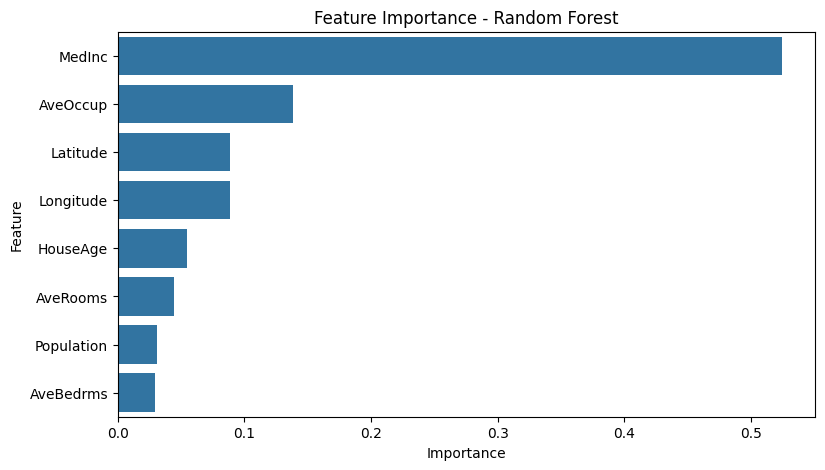

In [53]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance - Random Forest')
plt.show()

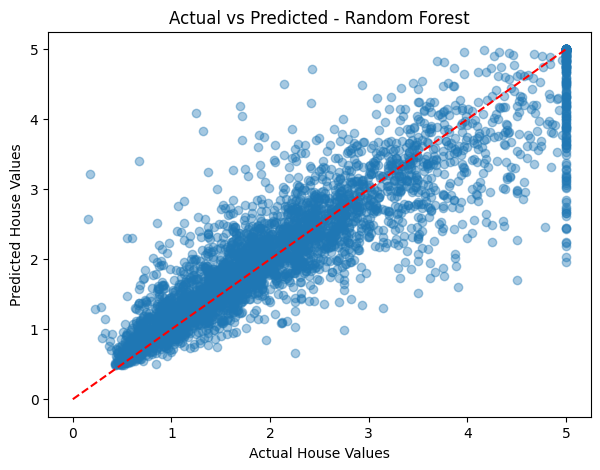

In [55]:
plt.figure(figsize=(7,5))

plt.scatter(y_test, rf_pred, alpha=0.4)

plt.plot([0, 5], [0, 5], color='red', linestyle='--')

plt.xlabel('Actual House Values')
plt.ylabel('Predicted House Values')
plt.title('Actual vs Predicted - Random Forest')

plt.show()

again chekcing overfitting

In [56]:
print("Training R2:", rf.score(X_train, y_train))
print("Testing R2:", rf.score(X_test, y_test))

Training R2: 0.9735726320302575
Testing R2: 0.8051230593157366


In [57]:
rf_tuned = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=4,
    random_state=42,
    n_jobs=-1
)

rf_tuned.fit(X_train, y_train)

train_score = rf_tuned.score(X_train, y_train)
test_score = rf_tuned.score(X_test, y_test)

print("Training R2:", train_score)
print("Testing R2:", test_score)

Training R2: 0.9129290176546533
Testing R2: 0.7990006584751298


In [58]:
from sklearn.model_selection import cross_val_score

models = {
    'Original RF': rf,
    'Tuned RF': rf_tuned
}

for name, model in models.items():
    scores = cross_val_score(
        model, X_train, y_train,
        cv=5, scoring='r2', n_jobs=-1
    )

    print(name)
    print("CV Scores:", scores)
    print("Mean CV R2:", scores.mean())
    print()

Original RF
CV Scores: [0.80899315 0.79381357 0.80828862 0.80440441 0.8051215 ]
Mean CV R2: 0.8041242497453812

Tuned RF
CV Scores: [0.80355276 0.79261777 0.80234033 0.80159004 0.80051347]
Mean CV R2: 0.8001228752254009



In [59]:
import joblib

joblib.dump(rf, 'california_housing_model.pkl')

['california_housing_model.pkl']

In [60]:
loaded_model = joblib.load('california_housing_model.pkl')

prediction = loaded_model.predict(X_test.iloc[:5])

print("Predictions:", prediction)

Predictions: [0.5095    0.74161   4.9232571 2.52961   2.27369  ]


In [61]:
from google.colab import files

files.download('california_housing_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>